In [249]:
#Required Python Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [250]:
#Import dataset
df = pd.read_csv(r"/content/drive/MyDrive/Processed_Flipdata - Processed_Flipdata.csv")

In [251]:
#check dataset dimesnion
print("No. of Rows: ", df.shape[0])
print("No. of Columns: ", df.shape[1])

No. of Rows:  541
No. of Columns:  12


In [252]:
#check columns name
df.columns

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize'],
      dtype='object')

In [253]:
#Rename for Error column name
df = df.rename(columns={'Battery_': 'Battery', 'Processor_': 'Processor', 'Prize': 'Price'})

In [254]:
#check the first 5 records
df.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor,Price
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,"7,299"
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,"11,999"
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,"5,649"
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,"8,999"


In [255]:
#Remove an exported row index
df.drop("Unnamed: 0", axis=1, inplace=True)

In [256]:
#Price Column Value in object change in Numeric Value
df["Price"] = pd.to_numeric(
    df["Price"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

In [257]:
#Print Random Records
df.sample(10)

,Model,Colour,Memory,RAM,Battery,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor,Price
236,realme Narzo 50,Speed Black,128,6,5000,50MP,16MP,0,16.76,Mediatek Helio G96,12999
88,MOTOROLA G62 5G,Frosted Blue,128,8,5000,50MP,16MP,0,41.94,Qualcomm Snapdragon 695 5G,16499
308,Google Pixel 7a,Sea,128,8,4300,64MP,13MP,0,15.49,Tensor G2,43999
342,nothing phone 1,Black,128,8,4500,50MP,16MP,0,16.64,Qualcomm Snapdragon 778G+,29499
34,POCO C55,Forest Green,64,4,5000,50MP,5MP,0,17.04,Mediatek Helio G85,7749
464,realme GT 2,Steel Black,256,2,5000,50MP,16MP,0,16.81,Qualcomm Snapdragon 888,32299
191,realme C33 2023,Night Sea,64,4,5000,50MP,5MP,0,16.51,Unisoc T612,9999
302,MOTOROLA Edge 30,Aurora Green,128,8,4020,50MP,32MP,0,16.64,Qualcomm Snapdragon 778G Plus,24999
17,POCO C51,Power Black,64,4,5000,8MP,5MP,0,16.56,Helio G36,6999
21,vivo T2x 5G,Marine Blue,128,8,5000,50MP,8MP,0,16.71,Dimensity 6020,15999


In [258]:
#check data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Model          541 non-null    object 
 1   Colour         541 non-null    object 
 2   Memory         541 non-null    int64  
 3   RAM            541 non-null    int64  
 4   Battery        541 non-null    int64  
 5   Rear Camera    541 non-null    object 
 6   Front Camera   541 non-null    object 
 7   AI Lens        541 non-null    int64  
 8   Mobile Height  541 non-null    float64
 9   Processor      541 non-null    object 
 10  Price          541 non-null    int64  
dtypes: float64(1), int64(5), object(5)
memory usage: 46.6+ KB


In [259]:
#check generate stastics describe
df.describe()

,Memory,RAM,Battery,AI Lens,Mobile Height,Price
count,541.000000,541.000000,541.000000,541.000000,541.000000,541.000000
mean,110.550832,5.397412,4871.587800,0.062847,16.431201,16228.375231
std,60.600694,1.984923,780.148862,0.242911,2.523553,10793.588322
min,16.000000,2.000000,800.000000,0.000000,4.500000,920.000000
25%,64.000000,4.000000,5000.000000,0.000000,16.510000,9290.000000
50%,128.000000,6.000000,5000.000000,0.000000,16.710000,13499.000000
75%,128.000000,8.000000,5000.000000,0.000000,16.940000,19280.000000
max,256.000000,8.000000,7000.000000,1.000000,41.940000,80999.000000


In [260]:
#finding missing Value
df.isnull().sum()

,0
Model,0
Colour,0
Memory,0
RAM,0
Battery,0
Rear Camera,0
Front Camera,0
AI Lens,0
Mobile Height,0
Processor,0


In [261]:
#Dublicates Records analysis
duplicates = df.duplicated().sum()
print("Dublicated Records: ", duplicates  )

Dublicated Records:  10


In [262]:
df[df.duplicated()]

,Model,Colour,Memory,RAM,Battery,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor,Price
27,vivo T2x 5G,Marine Blue,128,6,5000,50MP,8MP,0,16.71,Dimensity 6020,13999
48,MOTOROLA e32,Arctic Blue,64,4,5000,50MP,8MP,0,16.51,Mediatek Helio G37,7999
91,SAMSUNG Galaxy F14 5G,B.A.E. Purple,128,4,6000,50MP,13MP,0,16.76,"Exynos 1330, Octa Core",13490
132,SAMSUNG Galaxy F14 5G,OMG Black,128,6,6000,50MP,13MP,0,16.76,"Exynos 1330, Octa Core",14490
247,redmi min,M3),16,4,1000,0MP,0MP,0,4.57,Spreadtrum,920
344,Tecno Spark 9T,Turquoise Cyan,64,4,5000,50MP,8MP,0,16.76,MediaTek Helio G35,9290
352,POCO X4 Pro 5G,Laser Black,128,8,5000,64MP,16MP,0,16.94,Qualcomm Snapdragon 695 5G,19499
424,realme C30s,Stripe Black,64,4,5000,8MP,5MP,0,16.51,Unisoc SC9863A/ Unisoc SC9863A1,8499
437,vivo Y100 5G,Pacific Blue,128,8,4500,64MP,16MP,0,16.21,Mediatek Dimensity 900,23999
480,POCO C31,Royal Blue,64,4,5000,13MP,5MP,0,16.59,MediaTek G35,8999


In [263]:
#Duplicated Rows
print(df[df.duplicated(keep=False)].sort_values(by="Model"))

                     Model          Colour  Memory  RAM  Battery Rear Camera  \
46            MOTOROLA e32     Arctic Blue      64    4     5000        50MP   
48            MOTOROLA e32     Arctic Blue      64    4     5000        50MP   
480               POCO C31      Royal Blue      64    4     5000        13MP   
479               POCO C31      Royal Blue      64    4     5000        13MP   
350         POCO X4 Pro 5G     Laser Black     128    8     5000        64MP   
352         POCO X4 Pro 5G     Laser Black     128    8     5000        64MP   
90   SAMSUNG Galaxy F14 5G   B.A.E. Purple     128    4     6000        50MP   
91   SAMSUNG Galaxy F14 5G   B.A.E. Purple     128    4     6000        50MP   
130  SAMSUNG Galaxy F14 5G       OMG Black     128    6     6000        50MP   
132  SAMSUNG Galaxy F14 5G       OMG Black     128    6     6000        50MP   
332         Tecno Spark 9T  Turquoise Cyan      64    4     5000        50MP   
344         Tecno Spark 9T  Turquoise Cy

In [264]:
#Drop Dupliacted Rows
df = df.drop_duplicates(keep=False)

In [265]:
#After Drop Duplictes Value Check
duplicates = df.duplicated().sum()
print("Dublicated Records: ", duplicates  )

Dublicated Records:  0


In [266]:
#find Numerical and Categotrical columns
numeric_columns = df.select_dtypes(include=['number']).columns
print("Numerical Columns: ")
print(list(numeric_columns))

cat_columns = df.select_dtypes(exclude=['number']).columns
print("\nCategotrical Columns: ")
print(list(cat_columns))

Numerical Columns: 
['Memory', 'RAM', 'Battery', 'AI Lens', 'Mobile Height', 'Price']

Categotrical Columns: 
['Model', 'Colour', 'Rear Camera', 'Front Camera', 'Processor']


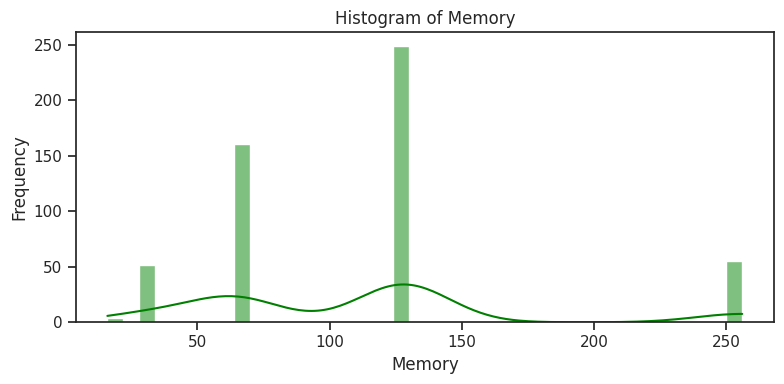

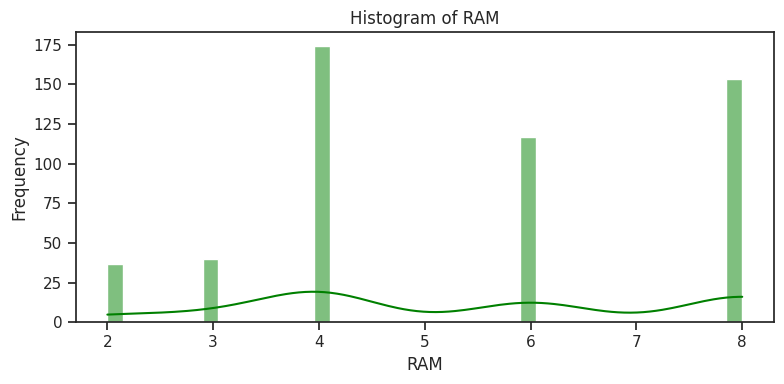

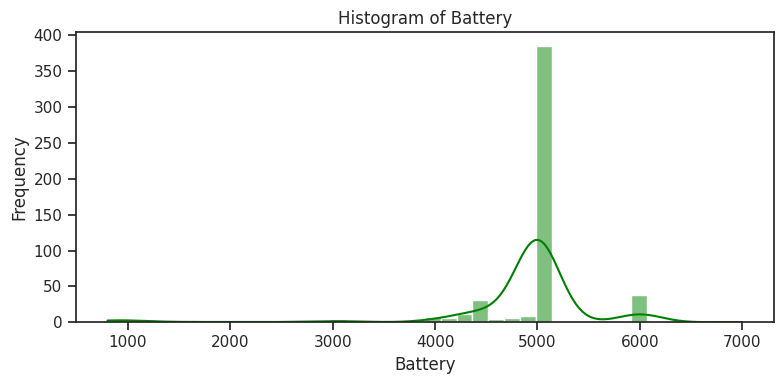

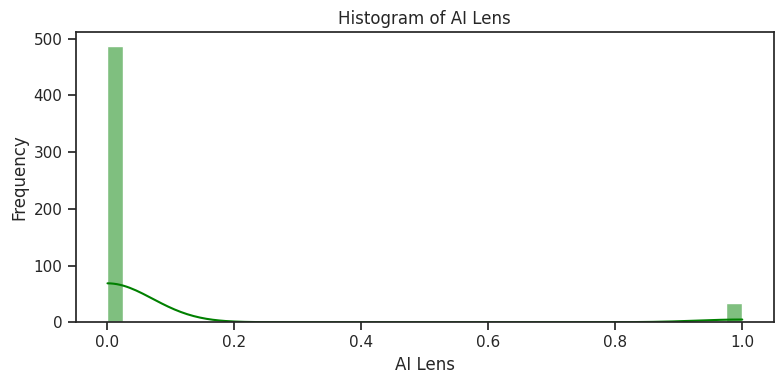

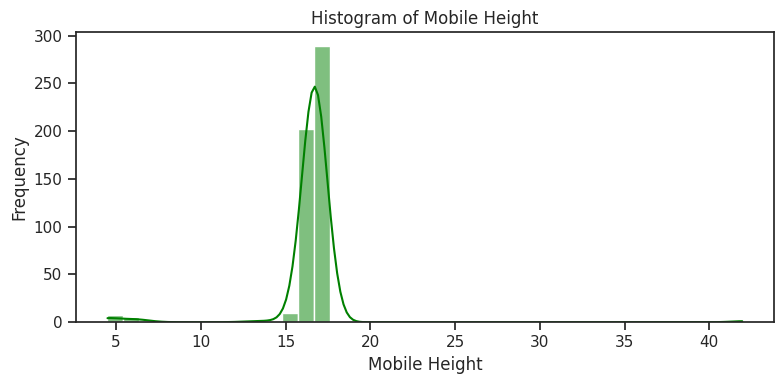

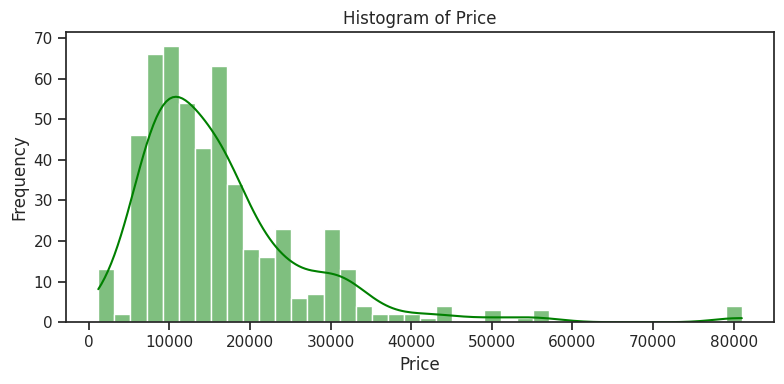

In [267]:
#Histogram for Numerical columns
for col in numeric_columns:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], bins=40, color="Green" , kde=True)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

In [268]:
#Categorical Variables Analysis
categorical_var = [
    "Model",
    "Colour",
    "Rear Camera",
    "Front Camera",
    "Processor"
]
for cat_col in categorical_var:
  print(f"\n----------- {cat_col} ----------")
  display(df[cat_col].value_counts().to_frame("Count"))


----------- Model ----------


,Count
Model,
realme C55,9
REDMI Note 12 Pro 5G,9
vivo Y16,9
SAMSUNG Galaxy A14 5G,9
Infinix HOT 30i,8
...,...
SAMSUNG Galaxy A04e,1
SAMSUNG Galaxy S23 5G,1
LAVA Z21,1



----------- Colour ----------


,Count
Colour,
Yellow,12
Black,8
Power Black,8
Cool Blue,7
Midnight Black,7
...,...
Flame Red,1
Oxygen Green,1
Aquamarine Blue,1



----------- Rear Camera ----------


,Count
Rear Camera,
50MP,250
13MP,61
64MP,58
8MP,50
108MP,31
48MP,31
12MP,10
0MP,8
200MP,8



----------- Front Camera ----------


,Count
Front Camera,
16MP,160
5MP,131
8MP,123
13MP,45
32MP,22
0MP,14
50MP,7
12MP,6
60MP,4



----------- Processor ----------


,Count
Processor,
Qualcomm Snapdragon 680,33
Unisoc T612,21
Mediatek Helio A22,19
Mediatek Dimensity 1080,18
Mediatek Helio P35,16
...,...
6 Core,1
Dimensity 8200,1
Qualcomm SM6225 Snapdragon 680 4G (6 nm),1


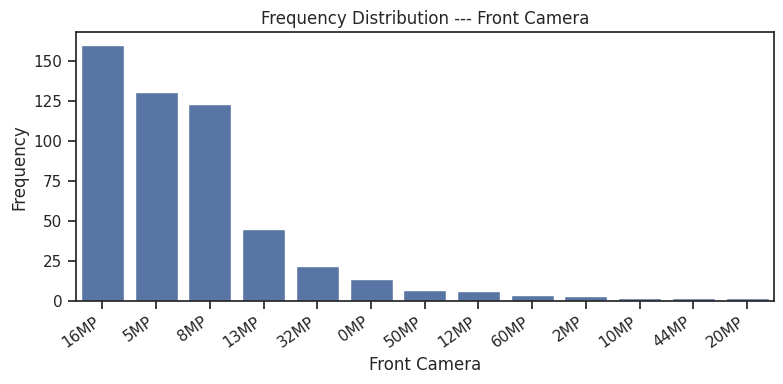

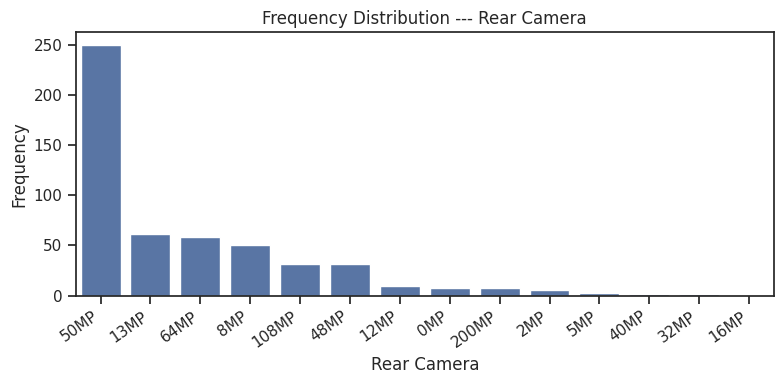

In [269]:
#Cateogarical Variable analysis
Categorical_col = ['Front Camera', 'Rear Camera']
for columns in Categorical_col:
  plt.figure(figsize=(8, 4))
  sns.countplot(data=df, x=df[columns], order=df[columns].value_counts().index)
  plt.title(f'Frequency Distribution --- {columns}')
  plt.xlabel(columns)
  plt.ylabel('Frequency')
  plt.xticks(rotation=35, ha="right")
  plt.tight_layout()
  plt.show()

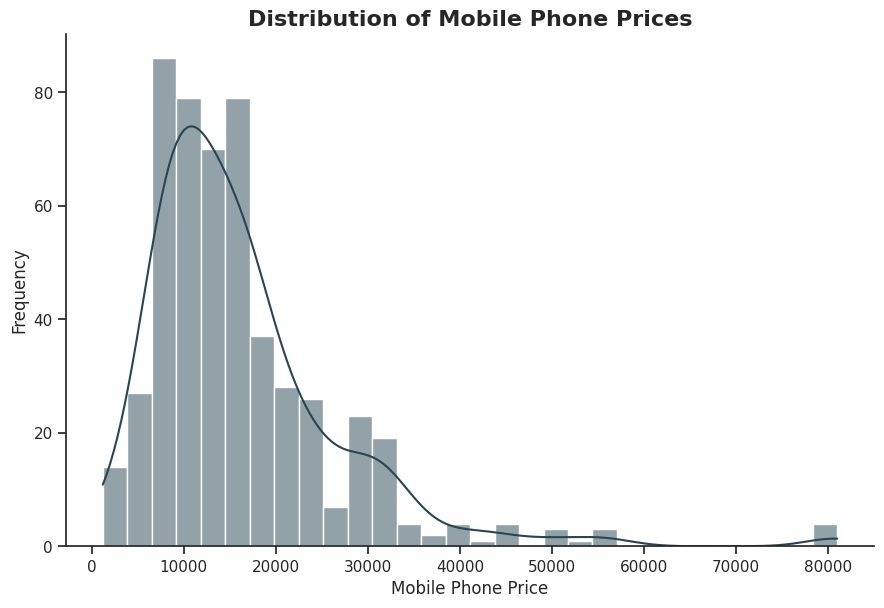

In [270]:
sns.displot(
    data=df,
    x="Price",
    kde=True,
    bins=30,
    color="#264653",
    height=6,
    aspect=1.5
)

plt.title("Distribution of Mobile Phone Prices",
          fontsize=16, fontweight="bold")
plt.xlabel("Mobile Phone Price")
plt.ylabel("Frequency")

plt.show()

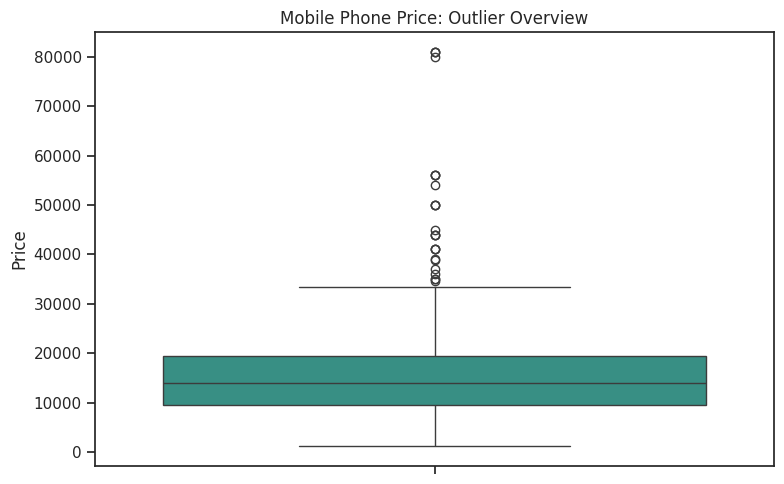

In [271]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df["Price"], color="#2A9D8F")
plt.title("Mobile Phone Price: Outlier Overview")
plt.tight_layout()
plt.show()

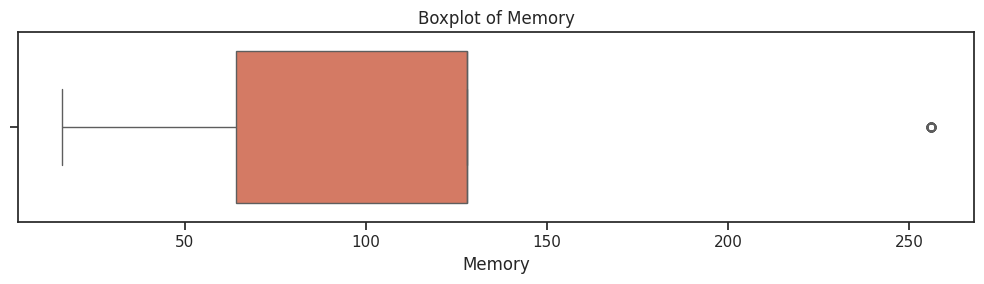

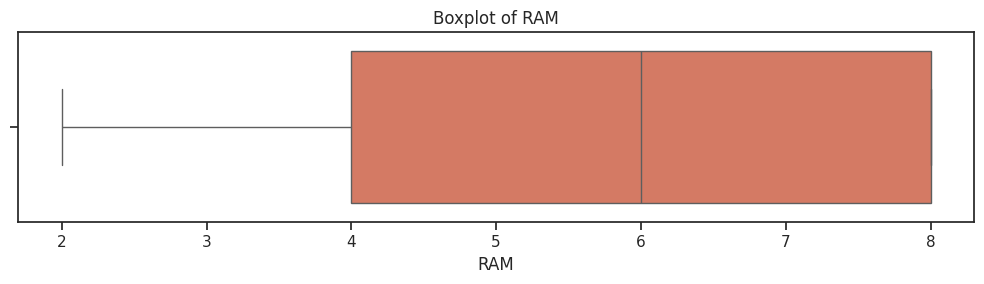

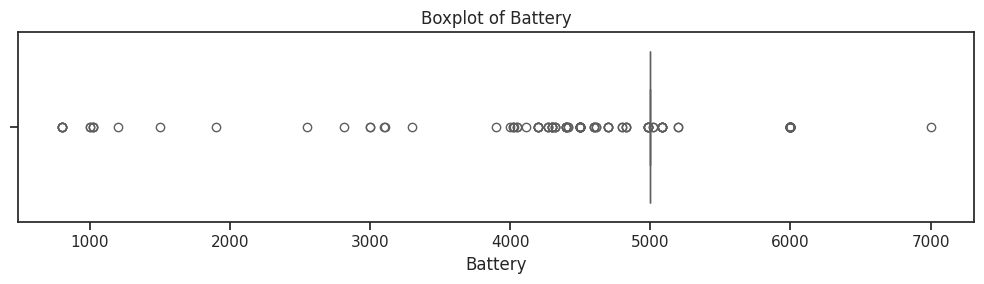

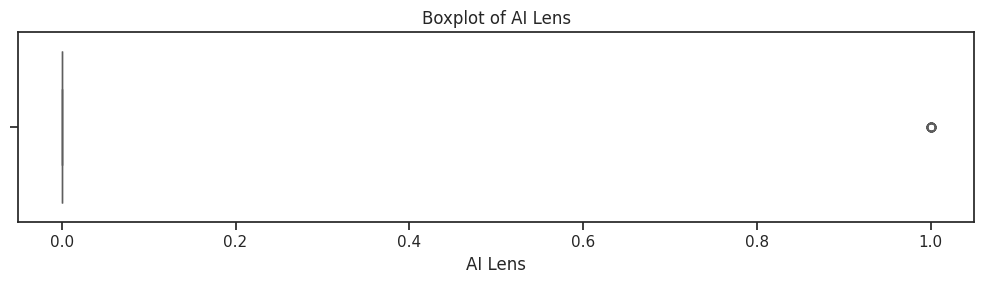

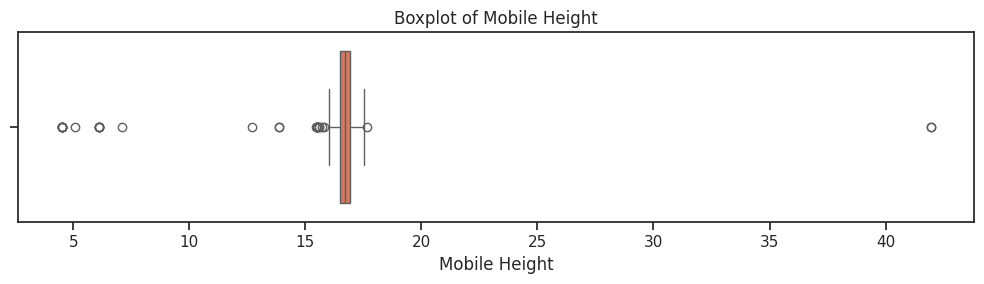

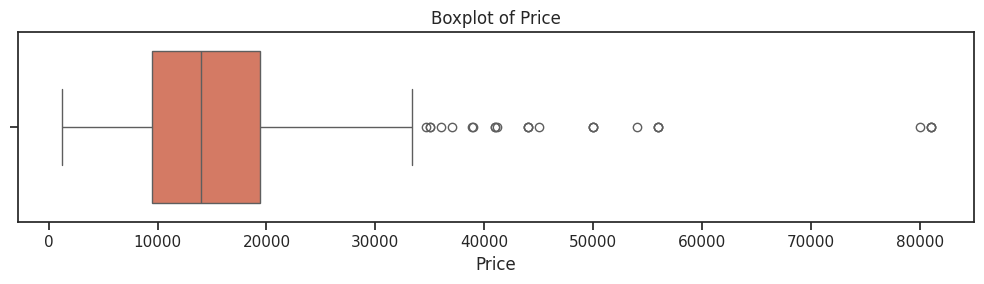

In [272]:
for col in numeric_columns:
  plt.figure(figsize=(10, 3))
  sns.boxplot(x=df[col], color="#E76F51")
  plt.title(f'Boxplot of {col}')
  plt.xlabel(col)
  plt.tight_layout()
  plt.show()

**Bivariate Analysis**


Correlation Matrix:
               Memory    RAM  Battery  AI Lens  Mobile Height  Price
Memory          1.000  0.624   -0.089   -0.099          0.038  0.560
RAM             0.624  1.000   -0.121   -0.085          0.085  0.527
Battery        -0.089 -0.121    1.000    0.158          0.671 -0.059
AI Lens        -0.099 -0.085    0.158    1.000          0.050 -0.159
Mobile Height   0.038  0.085    0.671    0.050          1.000  0.160
Price           0.560  0.527   -0.059   -0.159          0.160  1.000


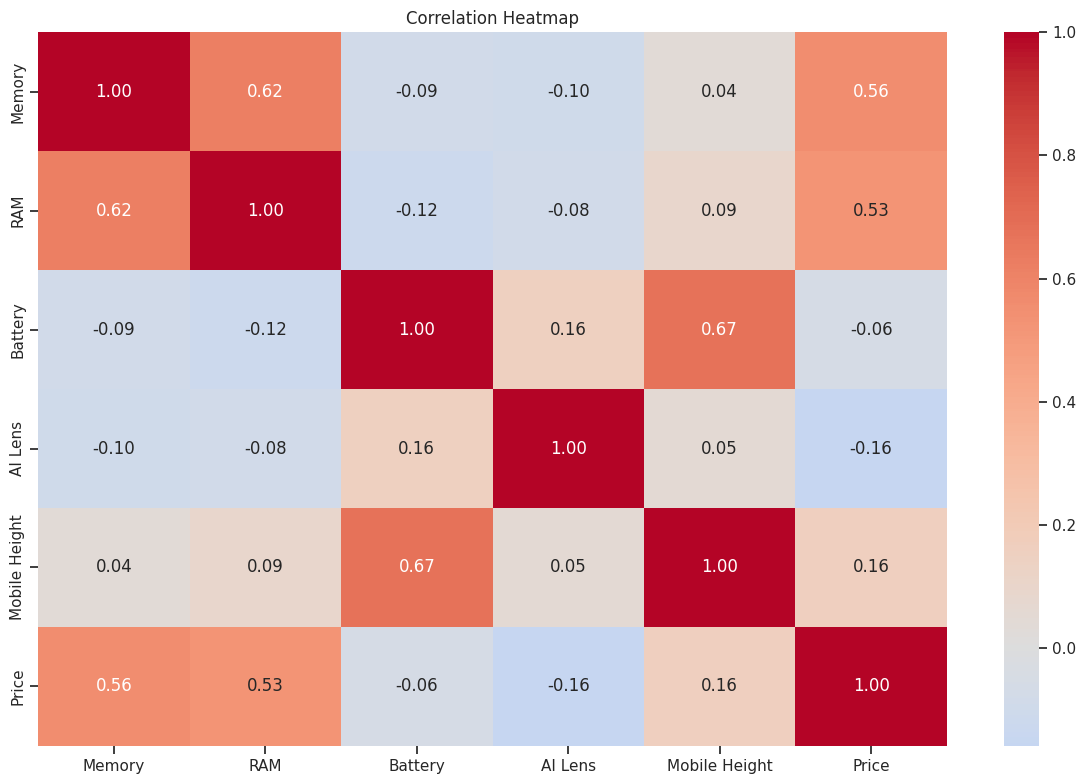

In [273]:
correlation = df[numeric_columns].corr()

print("\nCorrelation Matrix:")
print(correlation.round(3))

plt.figure(figsize=(12, 8))

sns.heatmap(
correlation,
annot=True,
fmt=".2f",
cmap="coolwarm",
center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

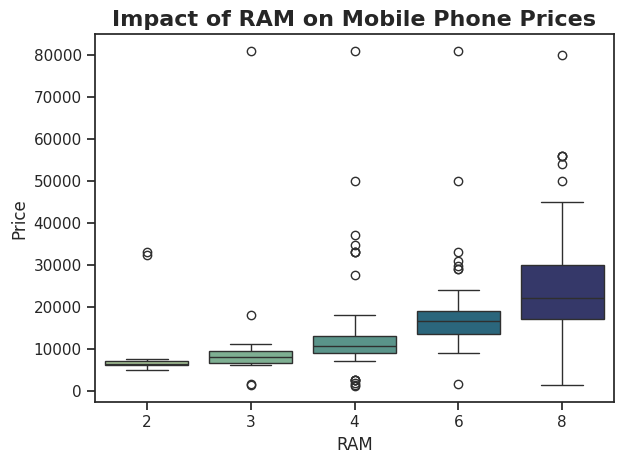

In [274]:
#Ram vs Price
sns.boxplot(
    data=df,
    x="RAM",
    y="Price",
    hue="RAM",
    palette="crest",
    legend=False
)

plt.title("Impact of RAM on Mobile Phone Prices",
          fontsize=16, fontweight="bold")
plt.xlabel("RAM")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

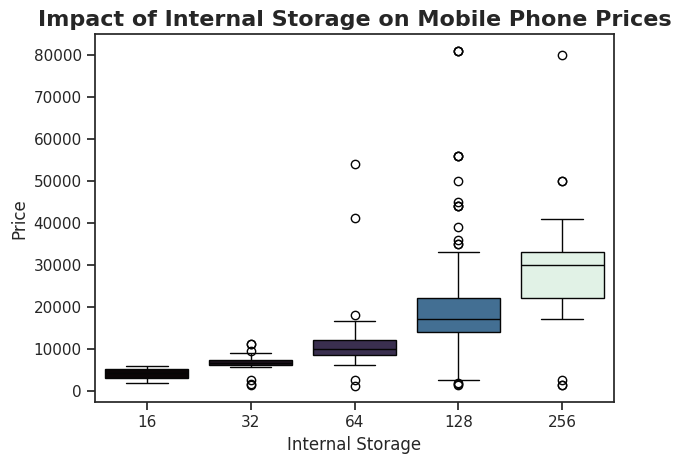

In [275]:
#Internal Memory vs Price
sns.boxplot(
    data=df,
    x="Memory",
    y="Price",
    hue="Memory",
    palette="mako",
    legend=False
)

plt.title("Impact of Internal Storage on Mobile Phone Prices",
          fontsize=16, fontweight="bold")
plt.xlabel("Internal Storage")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

In [276]:
print("\n--- PRICE SUMMARY BY NUMERIC FEATURE ---")
for col in [c for c in ["Memory", "RAM", "Battery_", "Rear Camera", "Front Camera", "AI Lens"] if c in df.columns]:
    print(f"\n{col}:")
    print(df.groupby(col, dropna=False)["Price"].agg(["count", "mean", "median"]).round(2).to_string())


--- PRICE SUMMARY BY NUMERIC FEATURE ---

Memory:
        count      mean   median
Memory                          
16          4   4011.50   4274.0
32         52   6749.29   6599.0
64        161  10678.83   9999.0
128       249  19721.82  16999.0
256        55  28002.71  29999.0

RAM:
     count      mean   median
RAM                          
2       37   7864.70   6299.0
3       40   9893.40   7994.5
4      174  12017.23  10599.0
6      117  17514.05  16499.0
8      153  24250.40  21999.0

Rear Camera:
             count      mean   median
Rear Camera                          
0MP              8   1417.62   1398.5
108MP           31  20688.74  19999.0
12MP            10  48768.00  43099.0
13MP            61   9094.70   8499.0
16MP             1   8940.00   8940.0
200MP            8  36124.00  32999.0
2MP              6   2583.50   2499.0
32MP             2  18999.00  18999.0
40MP             2  20999.00  20999.0
48MP            31  19905.39  17999.0
50MP           250  16523.93  14

**MULTIVARIATE ANALYSIS**



In [277]:
# Extract camera megapixels
for col in ["Rear Camera", "Front Camera"]:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.extract(r"(\d+(?:\.\d+)?)", expand=False),
        errors="coerce"
    )

df.dropna(subset=["Price"], inplace=True)

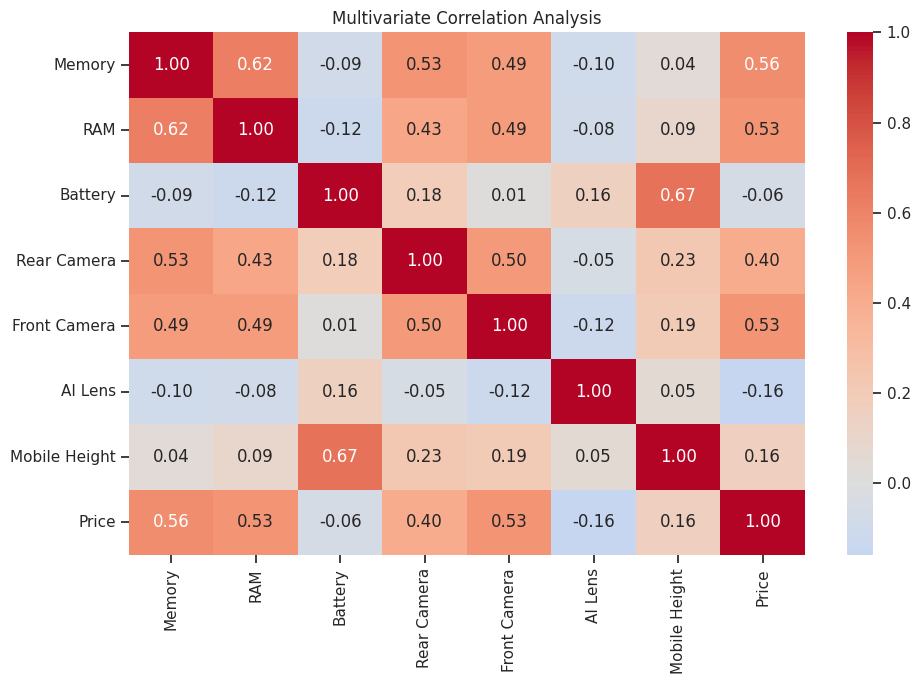

In [278]:
numeric_cols = [
    "Memory", "RAM", "Battery",
    "Rear Camera", "Front Camera",
    "AI Lens", "Mobile Height", "Price"
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Multivariate Correlation Analysis")
plt.tight_layout()
plt.show()

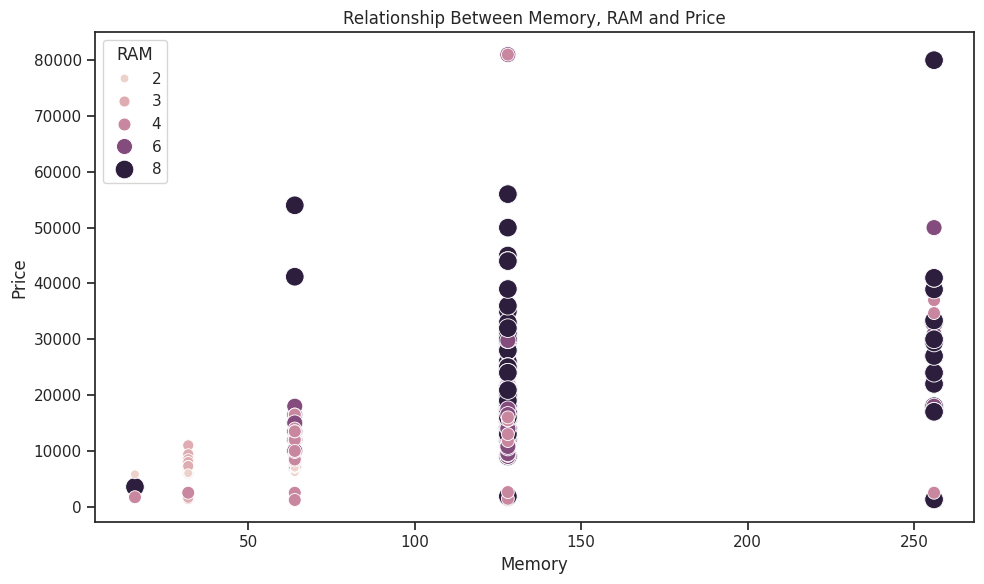

In [279]:
#Memory x RAM x Price
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Memory",
    y="Price",
    hue="RAM",
    size="RAM",
    sizes=(40, 180)
)

plt.title("Relationship Between Memory, RAM and Price")
plt.xlabel("Memory")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

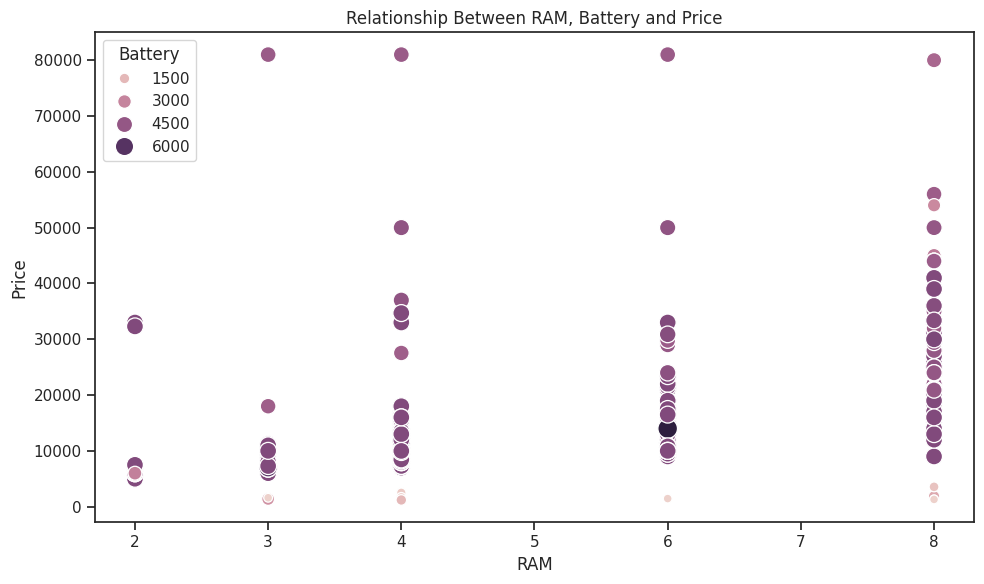

In [280]:
#RAM x Price x Battery
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="RAM",
    y="Price",
    hue="Battery",
    size="Battery",
    sizes=(40, 200)
)

plt.title("Relationship Between RAM, Battery and Price")
plt.tight_layout()
plt.show()

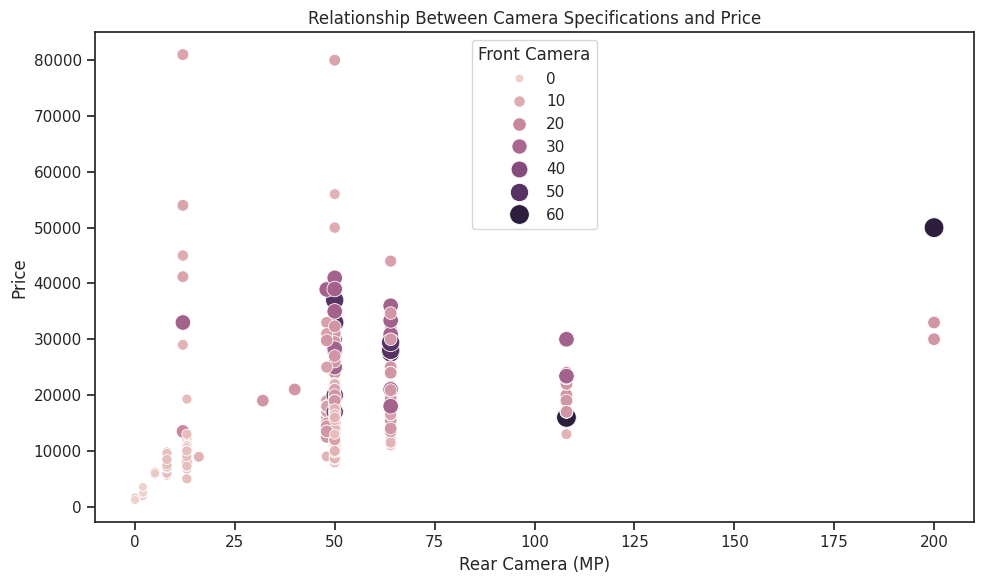

In [281]:
#Camera specifications and Price
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Rear Camera",
    y="Price",
    hue="Front Camera",
    size="Front Camera",
    sizes=(40, 200)
)

plt.title("Relationship Between Camera Specifications and Price")
plt.xlabel("Rear Camera (MP)")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

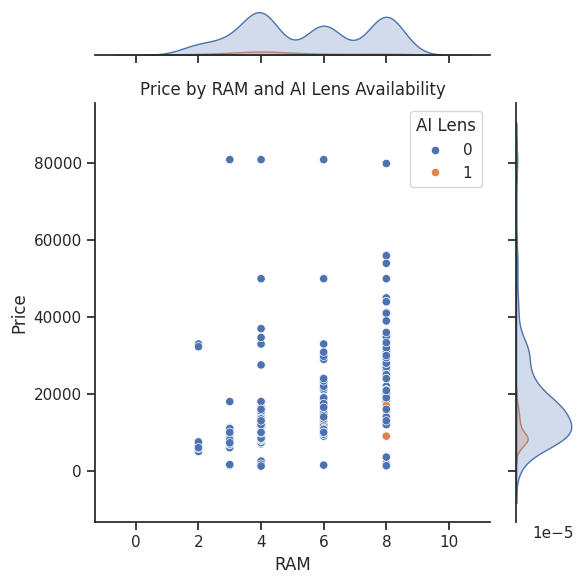

In [282]:
#RAM, AI Lens and Price
plt.figure(figsize=(10, 6))
sns.jointplot(data=df, x="RAM", y="Price", hue="AI Lens")

plt.title("Price by RAM and AI Lens Availability")
plt.xlabel("RAM")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

In [283]:
#Multivariate summary table
summary = (
    df.groupby(["RAM", "Memory"])
      .agg(
          Phone_Count=("Price", "count"),
          Average_Price=("Price", "mean"),
          Median_Price=("Price", "median"),
          Average_Battery=("Battery", "mean"),
          Average_Rear_Camera=("Rear Camera", "mean"),
          Average_Front_Camera=("Front Camera", "mean")
      )
      .reset_index()
      .sort_values("Average_Price", ascending=False)
)

print(summary.round(2))

    RAM  Memory  Phone_Count  Average_Price  Median_Price  Average_Battery  \
6     3     128            1       80999.00       80999.0          4323.00   
17    8      64            2       47599.00       47599.0          2962.50   
15    6     256            4       32967.75       31936.5          4660.00   
3     2     256            2       32649.00       32649.0          4990.00   
12    4     256            8       31340.25       32999.0          4298.75   
19    8     256           40       26856.48       26999.0          4650.25   
18    8     128          110       23066.41       19999.0          4753.59   
7     3     256            1       17999.00       17999.0          4200.00   
14    6     128           98       17533.65       16999.0          4989.01   
11    4     128           40       14353.28       12999.0          4983.58   
13    6      64           15       13265.00       13489.0          4900.00   
10    4      64          124       10176.99        9999.0       

#  FEATURES AND PREPROCESSING

In [284]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

In [285]:
X = df.drop(columns=["Price"])
y = df["Price"]
categorical_features = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

**TRAIN AND COMPARE REGRESSION MODELS**

In [286]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=4210
)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=4210, max_depth=8, min_samples_leaf=3
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=400, random_state=4210,
        min_samples_leaf=2, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=400, random_state=4210,
        min_samples_leaf=2, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=4210, n_estimators=200,
        learning_rate=0.04, max_depth=2
    ),
}

results = []
fitted_pipelines = {}
for name, estimator in models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions),
    })
    fitted_pipelines[name] = pipeline

results_df = pd.DataFrame(results).sort_values("MAE")
print("\n--- MODEL COMPARISON (lower MAE/RMSE is better; higher R2 is better) ---")
print(results_df.round(3).to_string(index=False))

best_name = results_df.iloc[0]["Model"]
best_pipeline = fitted_pipelines[best_name]
best_predictions = best_pipeline.predict(X_test)
print(f"\nBest model by test MAE: {best_name}")
print(f"Test MAE:  {mean_absolute_error(y_test, best_predictions):,.2f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, best_predictions)):,.2f}")
print(f"Test R²:   {r2_score(y_test, best_predictions):.3f}")



--- MODEL COMPARISON (lower MAE/RMSE is better; higher R2 is better) ---
            Model      MAE     RMSE    R2
      Extra Trees 1591.353 3538.933 0.899
    Random Forest 1682.266 3139.764 0.921
Linear Regression 2450.716 4242.698 0.855
Gradient Boosting 2660.761 3722.054 0.889
    Decision Tree 2842.902 5199.861 0.783

Best model by test MAE: Extra Trees
Test MAE:  1,591.35
Test RMSE: 3,538.93
Test R²:   0.899


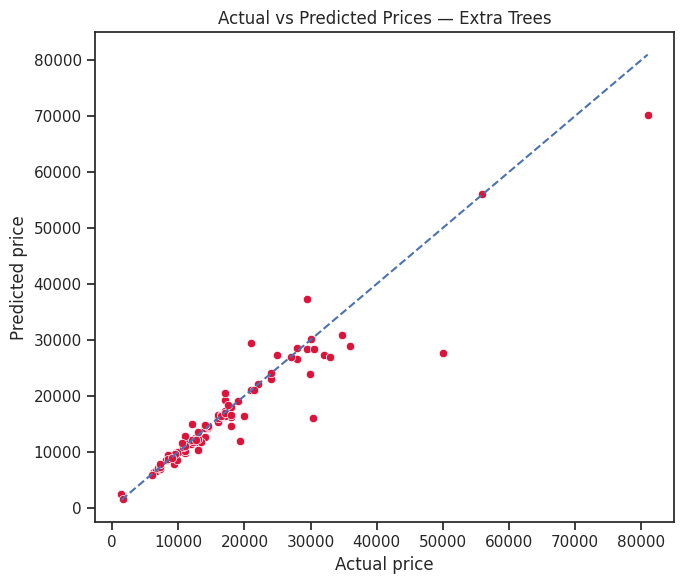

In [287]:
# Actual versus predicted chart.
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions,color="crimson")
low = min(float(y_test.min()), float(np.min(best_predictions)))
high = max(float(y_test.max()), float(np.max(best_predictions)))
plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title(f"Actual vs Predicted Prices — {best_name}")
plt.tight_layout()
plt.show()

In [288]:
# Save test predictions for review.
prediction_output = X_test.copy()
prediction_output["Actual_Prize"] = y_test
prediction_output["Predicted_Prize"] = best_predictions
prediction_output["Absolute_Error"] = np.abs(y_test.to_numpy() - best_predictions)

**FEATURE IMPORTANCE**


Calculating permutation importance on the held-out test set...

--- PERMUTATION FEATURE IMPORTANCE ---
      Feature  Importance_Mean  Importance_Std
       Memory         2257.664         253.507
 Front Camera         1971.105         215.314
        Model         1470.765         108.205
          RAM         1424.911         238.849
      Battery          873.830         128.865
    Processor          624.813          84.790
  Rear Camera          529.346          71.283
Mobile Height          200.974          63.683
      AI Lens           22.265           9.216
       Colour            6.346           1.499


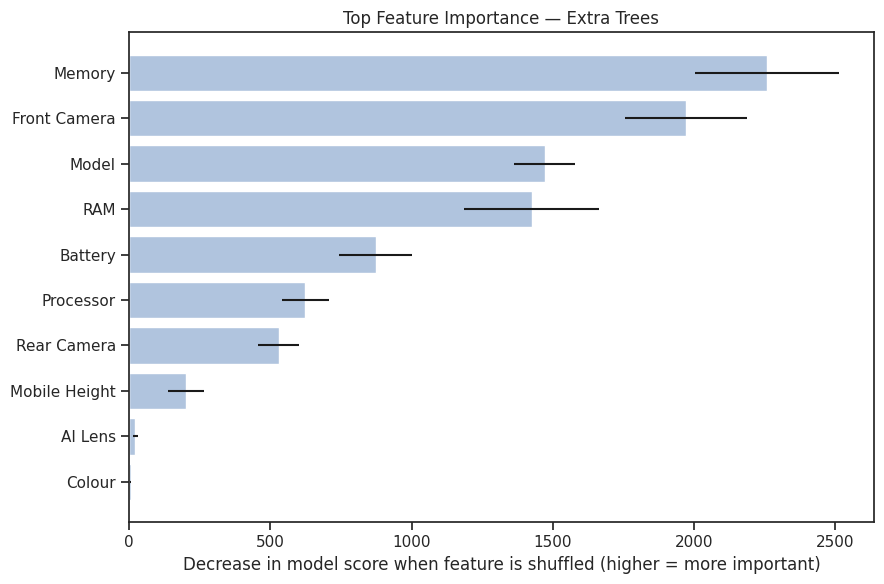

In [289]:
print("\nCalculating permutation importance on the held-out test set...")
perm = permutation_importance(
    best_pipeline, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=4210, n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std,
}).sort_values("Importance_Mean", ascending=False)
print("\n--- PERMUTATION FEATURE IMPORTANCE ---")
print(importance_df.round(3).to_string(index=False))

top = importance_df.head(15).sort_values("Importance_Mean")
plt.figure(figsize=(9, 6))
plt.barh(top["Feature"], top["Importance_Mean"], xerr=top["Importance_Std"], color="#b0c4de")
plt.xlabel("Decrease in model score when feature is shuffled (higher = more important)")
plt.title(f"Top Feature Importance — {best_name}")
plt.tight_layout()
plt.show()


In [290]:
#Encode categorical features and train the model
# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "encoder",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            categorical_features
        )
    ]
)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Create Random Forest model
model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "regressor",
        RandomForestRegressor(
            n_estimators=150,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=1
        )
    )
])

# Train model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [291]:
 #Calculate feature importance
# Calculate permutation importance
importance = permutation_importance(
    model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

# Create importance DataFrame
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean,
    "Std_Deviation": importance.importances_std
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

importance_df.index = importance_df.index + 1

print("FEATURE IMPORTANCE ANALYSIS")
print(importance_df.round(2))

FEATURE IMPORTANCE ANALYSIS
          Feature  Importance  Std_Deviation
1    Front Camera     3656.53         274.68
2          Memory     1291.30          49.33
3         Battery     1116.00         101.58
4     Rear Camera      734.25          63.52
5   Mobile Height      666.24          80.91
6             RAM      513.37          47.62
7       Processor      307.84          30.96
8           Model      270.08          20.85
9         AI Lens       15.66           2.19
10         Colour       -0.55           0.39


/tmp/ipykernel_3781/392328946.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


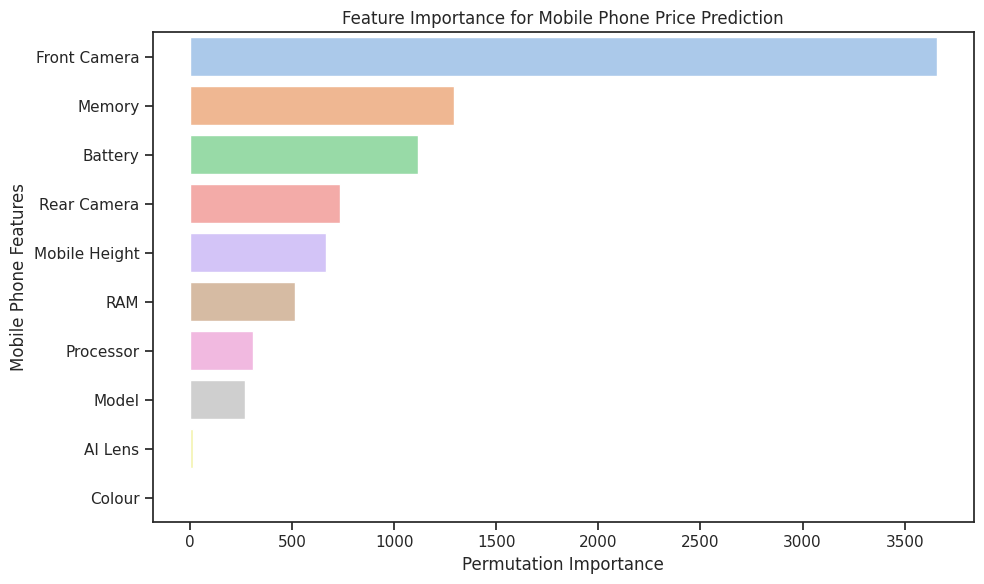

In [292]:
#Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.reset_index(drop=True),
    x="Importance",
    y="Feature", palette='pastel'
)

plt.title("Feature Importance for Mobile Phone Price Prediction")
plt.xlabel("Permutation Importance")
plt.ylabel("Mobile Phone Features")

plt.tight_layout()
plt.show()